<a href="https://colab.research.google.com/github/oninonins/Machine-learning-/blob/main/JS05/Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install hdbscan

In [18]:

import numpy as np
import matplotlib.pyplot as plt
import hdbscan

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [19]:
digits = load_digits()

X = digits.data
labels_true = digits.target

print("Jumlah sampel:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Jumlah kelas asli:", len(np.unique(labels_true)))

Jumlah sampel: 1797
Jumlah fitur: 64
Jumlah kelas asli: 10


In [20]:
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(
    "Total variasi yang dijelaskan PCA:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

Total variasi yang dijelaskan PCA: 21.59%


In [21]:
hdb = hdbscan.HDBSCAN(
    min_cluster_size=20,
    min_samples=5,
    metric="euclidean"
)

labels = hdb.fit_predict(X_scaled)

n_clusters = len(set(labels) - {-1})
n_noise = np.sum(labels == -1)

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)
print(f"Persentase noise: {n_noise / len(X) * 100:.2f}%")

Jumlah cluster: 9
Jumlah noise: 927
Persentase noise: 51.59%


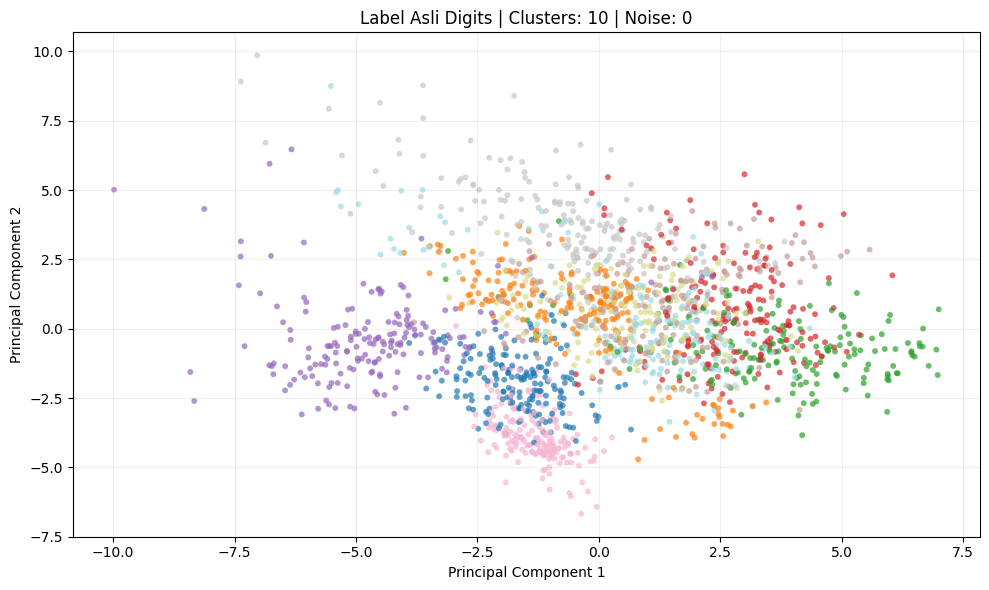

In [15]:
def plot_hdbscan(X_plot, labels, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 6))

    unique_labels = sorted(set(labels))
    cluster_labels = [label for label in unique_labels if label != -1]

    cmap = plt.get_cmap("tab20", max(len(cluster_labels), 1))
    color_map = {
        label: cmap(i)
        for i, label in enumerate(cluster_labels)
    }

    for label in unique_labels:
        mask = labels == label

        if label == -1:
            color = "black"
            marker = "x"
            name = "Noise (-1)"
        else:
            color = color_map[label]
            marker = "o"
            name = f"Cluster {label}"

        ax.scatter(
            X_plot[mask, 0],
            X_plot[mask, 1],
            c=[color],
            marker=marker,
            s=20,
            alpha=0.7,
            label=name
        )

    ax.set_title(
        f"HDBSCAN Clustering pada Digits Dataset (PCA)\n"
        f"Jumlah cluster: {n_clusters} | Noise: {n_noise}"
    )
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.grid(alpha=0.2)


fig, ax = plt.subplots(figsize=(12, 7))
plot_hdbscan(X_pca, labels, ax=ax)
plt.tight_layout()
plt.show()

Visualisasi PCA menunjukkan bahwa titik-titik tersebar dan beberapa kelompok saling tumpang tindih. PCA hanya menjelaskan 21,59% variasi data, sehingga visualisasi dua dimensi belum menggambarkan seluruh struktur data.
Hasil ini menunjukkan bahwa konfigurasi parameter min_cluster_size=20 dan min_samples=5 masih cukup konservatif dalam menentukan kepadatan data. Banyak sampel dianggap noise karena tidak memenuhi kriteria kepadatan HDBSCAN.

proporsi noise yang tinggi menunjukkan hasil clustering belum optimal